# Mission 05 - Hybrid retrieval and NotebookLM audit
Squadron Fei-Fei. Roles and measured limitations are in mission-05-doc.md. The lab record includes citation inspection, refusal probes and a two-minute Audio Overview excerpt.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / "run_all.py").exists():
    root = next(p / "Mission Five" for p in [root, *root.parents] if (p / "Mission Five" / "run_all.py").exists())
sys.path.insert(0, str(root))
import run_all
run_all.main()

01_HNSW_Vector_Index.py
Indexed 5000/25000
Indexed 10000/25000
Indexed 15000/25000
Indexed 20000/25000
Indexed 25000/25000
{
  "n": 25000,
  "dim": 768,
  "queries": 40,
  "seed": 505,
  "M": 12,
  "ef_construction": 32,
  "build_seconds": 8.611216749995947,
  "level_population": [
    25000,
    2033,
    173,
    12,
    2
  ],
  "vector_bytes": 76800000,
  "threads": 1,
  "distribution": "64 normalized Gaussian clusters; independent held-out queries"
}
{'ef': 32, 'hnsw_median_ms': 0.380396, 'hnsw_p95_ms': 0.6435291499999998, 'flat_median_ms': 1.2683335, 'flat_p95_ms': 1.4390437499999995, 'recall_at_10': 0.5725, 'mean_distance_evaluations': 338.5}
{'ef': 64, 'hnsw_median_ms': 0.523625, 'hnsw_p95_ms': 0.7954725999999999, 'flat_median_ms': 1.2619795, 'flat_p95_ms': 1.4808294999999994, 'recall_at_10': 0.6325, 'mean_distance_evaluations': 416.275}
{'ef': 128, 'hnsw_median_ms': 0.716104, 'hnsw_p95_ms': 1.2750795, 'flat_median_ms': 1.253437, 'flat_p95_ms': 1.4957333, 'recall_at_10': 0.6675

02_BM25_and_RRF_Combiner.py
concept_memory {'dense': ['semantic_memory', 'rag_memory', 'source_audio'], 'sparse': ['semantic_memory', 'rag_update', 'source_refusal'], 'fused': ['semantic_memory', 'rag_update', 'source_refusal']}
concept_global {'dense': ['graph_global', 'graph_reduce', 'rag_update'], 'sparse': ['graph_global', 'rrf_rank', 'rag_update'], 'fused': ['graph_global', 'rag_update', 'rrf_rank']}
exact_serial {'dense': ['ship_cooling_near', 'ship_cooling', 'lexical_manual'], 'sparse': ['ship_cooling'], 'fused': ['ship_cooling', 'ship_cooling_near', 'lexical_manual']}
exact_sensor {'dense': ['ship_spares', 'lexical_manual', 'source_refusal'], 'sparse': ['ship_sensor'], 'fused': ['ship_sensor', 'ship_spares', 'lexical_manual']}
mixed {'dense': ['ship_power', 'ship_sensor', 'ship_spares'], 'sparse': ['ship_power', 'ship_sensor', 'ship_cooling'], 'fused': ['ship_power', 'ship_sensor', 'ship_cooling']}



03_NotebookLM_RAG_Audit.py
{
  "notebook_url": "https://notebook.google.com/notebook/aeb75cf6-a203-47f7-ad6c-51d8df76a7df",
  "sources": [
    "Document_A_RAG.pdf",
    "Document_B_GraphRAG.pdf",
    "Document_C_Course_Website_Summary.pdf"
  ],
  "citation_occurrences": 17,
  "entailed_citations": 9,
  "citation_precision": 0.5294117647058824,
  "scoring_rule": "Strict single-span badge-level entailment of the whole attached sentence. Partial support counts as false; grouped citation support can be stronger than this deliberately conservative metric.",
  "negative_probes": 3,
  "refusals": 3
}
Audio status: evaluated



04_RAG_Provenance_and_Safety.py
Injection recall: 1.0 false-positive rate: 0.0
What maintenance interval applies to XQ-17B-904? => Its maintenance interval is 480 hours. The cooling assembly serial code XQ-17B-904 uses the Beryl coolant loop. {'context_relevance': 0.5, 'faithfulness': 1.0, 'answer_relevance': 0.6718493700027466, 'relevant_sentences': 3, 'retrieved_sentences': 6, 'supported_claims': 2, 'total_claims': 2, 'method': 'Cosine relevance thresholds; conservative exact-text support, not an NLI or fact-truth oracle'}
How does an assistant ground claims in an external archive? => When the supplied archive lacks the answer, a source-grounded assistant should acknowledge the missing information rather than invent ship specifications. Claims should be tied to inspectable passages. {'context_relevance': 0.75, 'faithfulness': 1.0, 'answer_relevance': 0.5893247723579407, 'relevant_sentences': 3, 'retrieved_sentences': 4, 'supported_claims': 2, 'total_claims': 2, 'method': 'Cosine rele

graph_assist.py
Entity graph: 22 nodes 38 edges; 6 communities
Beryl expansion: ['ship_power', 'ship_sensor']



In [2]:
import unittest
from test_ps05 import RetrievalTests
result = unittest.TextTestRunner(verbosity=1).run(unittest.defaultTestLoader.loadTestsFromTestCase(RetrievalTests))
assert result.wasSuccessful()

.

.

.

.

.

.

... (11 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 20 tests in 0.025s

OK


NotebookLM audit metrics: evidence/notebooklm_metrics.json


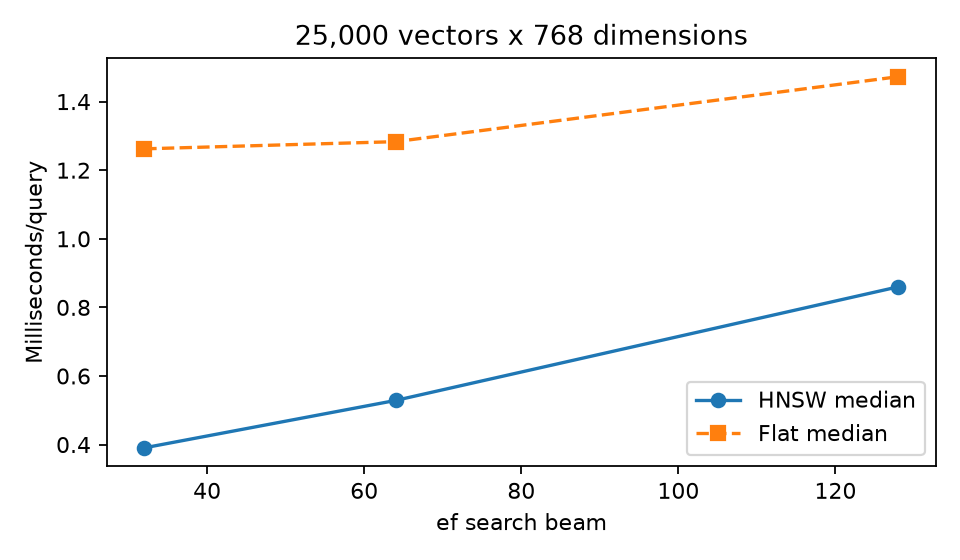

# Squadron Fei-Fei - Mission 05

| Member | Role | Responsibility |
|---|---|---|
| Bilal Younus | Systems Architect (Lead Engineer) | NumPy HNSW layers, cosine traversal and 25,000-vector benchmark |
| Danish Hafeez | Communications & Protocol Officer | BM25, exact identifiers and reciprocal rank fusion |
| Anas Arshad | Data & Payload Specialist | Three-source NotebookLM lab, citations, refusal probes and Audio Overview audit |
| Shahzaib Ahmed | Security & Ethics Sentinel | Indirect injection quarantine, RAG Triad scoring and provenance traces |


In [3]:
import json
from IPython.display import display, Markdown, Image
print("NotebookLM audit metrics: evidence/notebooklm_metrics.json")
display(Image(filename=str(root / "evidence/latency.png")))
display(Markdown((root / "00_Team_Roles.md").read_text()))